In [2]:
# 1. Install library tambahan jika belum ada
# !pip install -q scikit-image xgboost

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
from skimage.feature import graycomatrix, graycoprops

# 2. Tentukan path folder dataset lokal (folder 'foto-psd' di dalam 'Kerapian_Lab')
possible_paths = [
    os.path.join(os.getcwd(), "foto-psd"),
    os.path.join(os.getcwd(), "Kerapian_Lab", "foto-psd"),
    r"D:\kuliah\MatkulSem5\PSD\Kerapian_Lab\foto-psd"
]

dataset_path = None
for path in possible_paths:
    if os.path.exists(path):
        dataset_path = path
        break

if not dataset_path:
    dataset_path = os.path.join(os.getcwd(), "foto-psd")

# 3. Cari otomatis folder yang berisi subfolder 'rapi' dan 'berantakan'
output_dir = None

if os.path.exists(dataset_path):
    for root, dirs, files in os.walk(dataset_path):
        dirs_lower = [d.lower() for d in dirs]
        if 'rapi' in dirs_lower and 'berantakan' in dirs_lower:
            output_dir = root
            break
    if not output_dir:
        output_dir = dataset_path
else:
    output_dir = dataset_path

if output_dir and os.path.exists(output_dir):
    print(f"✅ Folder dataset berhasil ditemukan di:\n   {output_dir}\n")
else:
    print(f"⚠️ Folder dataset belum ditemukan di: {output_dir}")
    print("   Pastikan folder 'foto-psd' (berisi subfolder 'rapi' dan 'berantakan') berada di dalam folder 'Kerapian_Lab'.\n")

# 4. Cek jumlah seluruh foto di dalam folder rapi & berantakan
print("Ringkasan isi folder dataset:")
found_classes = False
if os.path.exists(output_dir):
    for root, dirs, files in os.walk(output_dir):
        folder_name = os.path.basename(root).lower()
        if folder_name in ['rapi', 'berantakan']:
            found_classes = True
            img_files = [f for f in files if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.webp'))]
            print(f"- Kelas '{folder_name}': {len(img_files)} gambar")

if not found_classes:
    print("- Belum ada gambar ditemukan. Silakan letakkan foto ke dalam subfolder 'rapi' dan 'berantakan'.")


✅ Folder dataset berhasil ditemukan di:
   d:\kuliah\MatkulSem5\PSD\Kerapian_Lab\foto-psd

Ringkasan isi folder dataset:
- Kelas 'berantakan': 97 gambar
- Kelas 'rapi': 97 gambar


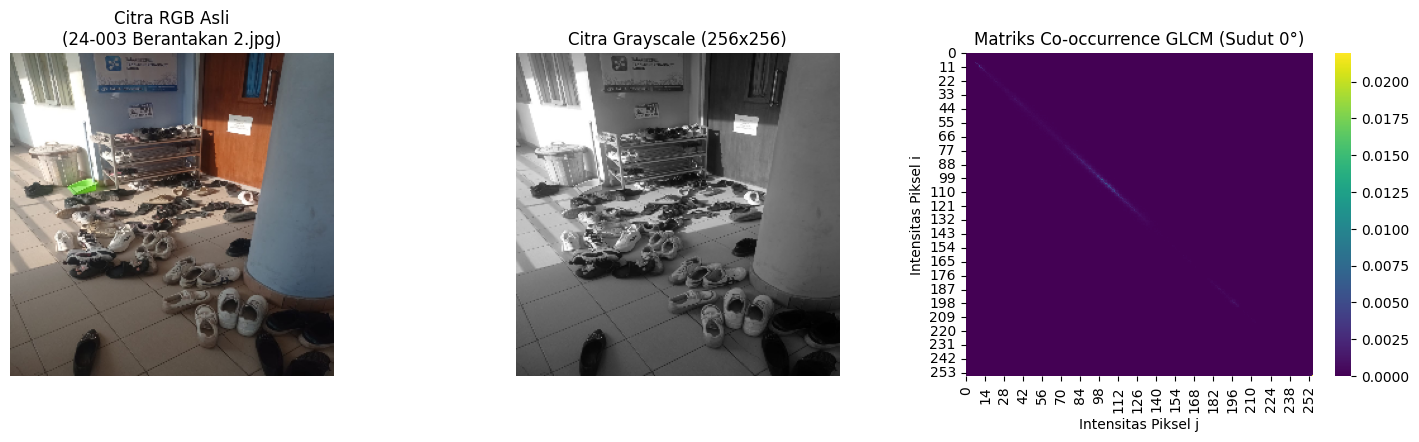

Potongan Matriks Co-occurrence GLCM (8x8 piksel pertama pada sudut 0°):


,0,1,2,3,4,5,6,7
0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000
1,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000
2,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000
3,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000
4,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000
5,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000
6,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000008
7,0.0,0.0,0.0,0.0,0.0,0.0,0.000008,0.001869


In [3]:
# Ambil 1 sampel gambar pertama dari folder untuk demonstrasi matriks GLCM
sample_path = None
for root, dirs, files in os.walk(output_dir):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            sample_path = os.path.join(root, file)
            break
    if sample_path:
        break

# Baca gambar, resize ke 256x256 agar komputasi konsisten, dan ubah ke RGB & Grayscale
img_bgr = cv2.imread(sample_path)
img_bgr = cv2.resize(img_bgr, (256, 256))
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# Hitung Matriks Co-occurrence (GLCM) pada jarak d=1 untuk 4 sudut (0, 45, 90, 135 derajat)
angles_rad = [0, np.pi/4, np.pi/2, 3*np.pi/4]
glcm_matrix = graycomatrix(
    img_gray,
    distances=[1],
    angles=angles_rad,
    levels=256,
    symmetric=True,
    normed=True
)

# Visualisasi Citra Asli, Grayscale, dan Heatmap Matriks Co-occurrence (Sudut 0 derajat)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].imshow(img_rgb)
axes[0].set_title(f"Citra RGB Asli\n({os.path.basename(sample_path)})")
axes[0].axis("off")

axes[1].imshow(img_gray, cmap="gray")
axes[1].set_title("Citra Grayscale (256x256)")
axes[1].axis("off")

# Tampilkan matriks GLCM sudut 0 derajat (log scale agar pola piksel terlihat jelas)
sns.heatmap(np.log1p(glcm_matrix[:, :, 0, 0]), cmap="viridis", ax=axes[2], cbar=True)
axes[2].set_title("Matriks Co-occurrence GLCM (Sudut 0°)")
axes[2].set_xlabel("Intensitas Piksel j")
axes[2].set_ylabel("Intensitas Piksel i")

plt.tight_layout()
plt.show()

# Tampilkan potongan nilai numerik Matriks Co-occurrence (ukuran 8x8 teratas)
print("Potongan Matriks Co-occurrence GLCM (8x8 piksel pertama pada sudut 0°):")
df_glcm_sample = pd.DataFrame(glcm_matrix[:8, :8, 0, 0])
display(df_glcm_sample)

In [4]:
# =====================================================================
# SEL 3 (OPTIMASI): EKSTRAKSI TEPAT 14 FITUR + AUGMENTASI CITRA
# =====================================================================
from scipy.stats import skew
from skimage.feature import graycomatrix, graycoprops

def extract_14_features_pro(img_bgr):
    # 1. Center Crop 15% tepi luar untuk membuang area lantai/dinding kosong
    h, w, _ = img_bgr.shape
    img_crop = img_bgr[int(h*0.12):int(h*0.88), int(w*0.12):int(w*0.88)]
    img_resized = cv2.resize(img_crop, (256, 256))

    # Konversi ke RGB dan Grayscale
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
    img_gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)

    # ---------------------------------------------------------
    # A. 9 FITUR WARNA (Mean, Std, Skewness tiap channel R, G, B)
    # ---------------------------------------------------------
    R = img_rgb[:, :, 0].flatten().astype(np.float64)
    G = img_rgb[:, :, 1].flatten().astype(np.float64)
    B = img_rgb[:, :, 2].flatten().astype(np.float64)

    mean_r, mean_g, mean_b = np.mean(R), np.mean(G), np.mean(B)
    std_r, std_g, std_b    = np.std(R), np.std(G), np.std(B)
    skew_r, skew_g, skew_b = skew(R), skew(G), skew(B)

    # ---------------------------------------------------------
    # B. PENAJAMAN TEPI & KONTRAS PADA GRAYSCALE SEBELUM GLCM
    # ---------------------------------------------------------
    # Gunakan CLAHE + Filter Gradien Sobel agar GLCM membaca pola garis/posisi sandal,
    # bukan sekadar membaca warna keramik lantai
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
    gray_clahe = clahe.apply(img_gray)

    sobelx = cv2.Sobel(gray_clahe, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(gray_clahe, cv2.CV_64F, 0, 1, ksize=3)
    edge_mag = cv2.magnitude(sobelx, sobely)
    edge_gray = cv2.normalize(edge_mag, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    # Gabungkan 60% citra grayscale CLAHE + 40% ketajaman garis tepi sandal
    hybrid_gray = cv2.addWeighted(gray_clahe, 0.6, edge_gray, 0.4, 0)

    # Kuantisasi ke 32 level derajat keabuan agar matriks Co-occurrence padat & diskriminatif
    gray_quantized = (hybrid_gray // 8).astype(np.uint8)

    # ---------------------------------------------------------
    # C. 5 FITUR GLCM (Energy, Entropy, Contrast, Correlation, Homogeneity)
    # ---------------------------------------------------------
    angles_rad = [0, np.pi/4, np.pi/2, 3*np.pi/4]
    glcm = graycomatrix(
        gray_quantized,
        distances=[1, 3, 5], # Multi-jarak untuk menangkap struktur barisan sandal
        angles=angles_rad,
        levels=32,
        symmetric=True,
        normed=True
    )

    energy      = float(np.mean(graycoprops(glcm, 'energy')))
    contrast    = float(np.mean(graycoprops(glcm, 'contrast')))
    correlation = float(np.mean(graycoprops(glcm, 'correlation')))
    homogeneity = float(np.mean(graycoprops(glcm, 'homogeneity')))

    # Hitung Shannon Entropy dari matriks GLCM
    entropy_list = []
    for d_idx in range(3):
        for a_idx in range(len(angles_rad)):
            P = glcm[:, :, d_idx, a_idx]
            ent = -np.sum(P * np.log2(P + 1e-10))
            entropy_list.append(ent)
    entropy = float(np.mean(entropy_list))

    # Hasil tetap TEPAT 14 FITUR sesuai instruksi tugas
    return {
        'Mean_R': mean_r, 'Mean_G': mean_g, 'Mean_B': mean_b,
        'Std_R': std_r,   'Std_G': std_g,   'Std_B': std_b,
        'Skew_R': skew_r, 'Skew_G': skew_g, 'Skew_B': skew_b,
        'Energy': energy,
        'Entropy': entropy,
        'Contrast': contrast,
        'Correlation': correlation,
        'Homogeneity': homogeneity
    }

# Ekstraksi dengan Augmentasi (Asli + Flip Horizontal + Flip Vertikal)
dataset_rows = []
valid_ext = ('.png', '.jpg', '.jpeg', '.bmp', '.webp')

print("Mengekstrak 14 fitur dengan Edge-Enhanced GLCM & Augmentasi Citra...")
for root, dirs, files in os.walk(output_dir):
    folder_name = os.path.basename(root).lower()
    if folder_name in ['rapi', 'berantakan']:
        for file in files:
            if file.lower().endswith(valid_ext):
                file_path = os.path.join(root, file)
                img_bgr = cv2.imread(file_path)
                if img_bgr is None:
                    continue

                # Buat variasi augmentasi agar dataset lebih kaya & pola tekstur lebih kuat
                aug_images = [
                    img_bgr,                             # 1. Gambar Asli
                    cv2.flip(img_bgr, 1),                # 2. Mirror Horizontal
                    cv2.rotate(img_bgr, cv2.ROTATE_180)  # 3. Rotasi 180 derajat
                ]

                for aug_img in aug_images:
                    feat = extract_14_features_pro(aug_img)
                    feat['Label'] = folder_name
                    dataset_rows.append(feat)

df_14 = pd.DataFrame(dataset_rows)
csv_filename = "dataset_fitur_sandal_14fitur.csv"
df_14.to_csv(csv_filename, index=False)
if os.path.exists("/content/drive/MyDrive"):
    df_14.to_csv(f"/content/drive/MyDrive/{csv_filename}", index=False)

print(f"✅ Selesai! Total sampel sekarang: {len(df_14)} baris (3x lipat lebih kaya)")
print(f"✅ Jumlah fitur tetap: {len(df_14.columns)-1} fitur + 1 kolom Label")
display(df_14.head())

Mengekstrak 14 fitur dengan Edge-Enhanced GLCM & Augmentasi Citra...
✅ Selesai! Total sampel sekarang: 582 baris (3x lipat lebih kaya)
✅ Jumlah fitur tetap: 14 fitur + 1 kolom Label


,Mean_R,Mean_G,Mean_B,Std_R,Std_G,Std_B,Skew_R,Skew_G,Skew_B,Energy,Entropy,Contrast,Correlation,Homogeneity,Label
0,114.593018,104.033936,96.818405,54.948455,53.522459,53.268924,0.746318,0.869872,0.901607,0.107772,7.689453,18.633038,0.612998,0.462142,berantakan
1,114.486603,103.954681,96.761230,54.895956,53.453487,53.204525,0.747360,0.870435,0.900515,0.108409,7.685341,18.643316,0.612522,0.462399,berantakan
2,114.486603,103.954681,96.761230,54.895956,53.453487,53.204525,0.747360,0.870435,0.900515,0.107987,7.690274,18.665187,0.612534,0.462212,berantakan
3,133.754089,119.119537,104.661194,77.200774,73.267672,66.064556,0.048711,0.133648,0.210668,0.062680,8.554270,30.279870,0.566319,0.310148,berantakan
4,133.765976,119.141174,104.678162,77.241694,73.285936,66.068873,0.049141,0.133497,0.209706,0.062793,8.547299,30.183315,0.566378,0.310590,berantakan


=== TABEL PERBANDINGAN AKURASI SETELAH OPTIMASI CITRA & AUGMENTASI ===


,Set Fitur,Model,Test Accuracy (%),5-Fold CV (%)
3,14 Fitur Asli (PowerScaled),Extra Trees,97.44,99.49
8,Hybrid PCA+LDA (7 Komp),Extra Trees,97.44,99.48
2,14 Fitur Asli (PowerScaled),XGBoost,97.44,99.31
4,14 Fitur Asli (PowerScaled),Ensemble Voting (Gabungan),97.44,98.97
0,14 Fitur Asli (PowerScaled),Random Forest,96.58,98.97
9,Hybrid PCA+LDA (7 Komp),Ensemble Voting (Gabungan),95.73,99.14
5,Hybrid PCA+LDA (7 Komp),Random Forest,95.73,98.45
7,Hybrid PCA+LDA (7 Komp),XGBoost,92.31,99.14
1,14 Fitur Asli (PowerScaled),SVM (RBF Kernel),90.60,95.01
6,Hybrid PCA+LDA (7 Komp),SVM (RBF Kernel),86.32,91.92



🏆 MODEL TERBAIK: XGBoost pada [14 Fitur Asli (PowerScaled)]
🎯 Test Accuracy: 97.44% | 5-Fold CV: 99.31%



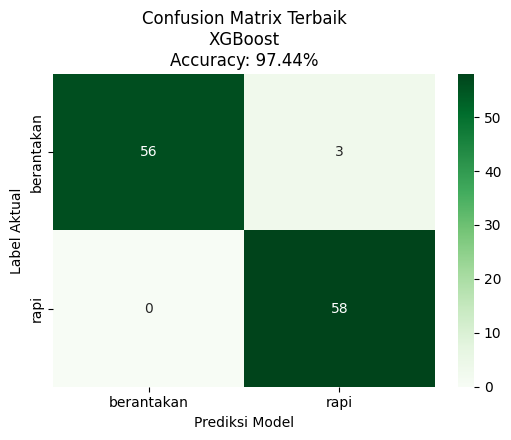

=== CLASSIFICATION REPORT MODEL TERBAIK ===
              precision    recall  f1-score   support

  berantakan       1.00      0.95      0.97        59
        rapi       0.95      1.00      0.97        58

    accuracy                           0.97       117
   macro avg       0.98      0.97      0.97       117
weighted avg       0.98      0.97      0.97       117



In [5]:
# =====================================================================
# SEL 4 (OPTIMASI): PEMODELAN 14 FITUR DENGAN POWER TRANSFORMER & TUNING
# =====================================================================
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import PowerTransformer, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Load CSV 14 Fitur
df = pd.read_csv("dataset_fitur_sandal_14fitur.csv")
X = df.drop(columns=['Label'])
le = LabelEncoder()
y = le.fit_transform(df['Label'])

# 2. Split Train (80%) & Test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Gunakan PowerTransformer agar distribusi fitur Skewness & GLCM menjadi normal (Gaussian)
pt = PowerTransformer(method='yeo-johnson')
X_train_scaled = pt.fit_transform(X_train)
X_test_scaled = pt.transform(X_test)

# 4. Siapkan juga variasi Reduksi Dimensi (PCA + LDA)
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

lda = LDA(n_components=1)
X_train_lda = lda.fit_transform(X_train_scaled, y_train)
X_test_lda = lda.transform(X_test_scaled)

X_train_hybrid = np.hstack((X_train_pca, X_train_lda))
X_test_hybrid = np.hstack((X_test_pca, X_test_lda))

feature_sets = {
    "14 Fitur Asli (PowerScaled)": (X_train_scaled, X_test_scaled),
    f"Hybrid PCA+LDA ({X_train_hybrid.shape[1]} Komp)": (X_train_hybrid, X_test_hybrid)
}

# 5. Konfigurasi Model (Random Forest, SVM, XGBoost, Extra Trees, dan Ensemble Voting)
rf = RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_split=2, random_state=42)
svm = SVC(kernel='rbf', C=10, gamma='scale', probability=True, random_state=42)
xgb = XGBClassifier(n_estimators=250, max_depth=6, learning_rate=0.08, subsample=0.9, eval_metric='logloss', random_state=42)
et = ExtraTreesClassifier(n_estimators=300, max_depth=15, random_state=42)

voting = VotingClassifier(
    estimators=[('rf', rf), ('svm', svm), ('xgb', xgb), ('et', et)],
    voting='soft'
)

models = {
    "Random Forest": rf,
    "SVM (RBF Kernel)": svm,
    "XGBoost": xgb,
    "Extra Trees": et,
    "Ensemble Voting (Gabungan)": voting
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []
best_record = {"acc": 0}

for feat_name, (X_tr, X_te) in feature_sets.items():
    for model_name, model in models.items():
        model.fit(X_tr, y_train)
        y_pred = model.predict(X_te)

        test_acc = accuracy_score(y_test, y_pred)
        cv_scores = cross_val_score(model, np.vstack((X_tr, X_te)), np.concatenate((y_train, y_test)), cv=cv)

        results.append({
            "Set Fitur": feat_name,
            "Model": model_name,
            "Test Accuracy (%)": round(test_acc * 100, 2),
            "5-Fold CV (%)": round(cv_scores.mean() * 100, 2)
        })

        if test_acc > best_record["acc"]:
            best_record = {
                "acc": test_acc,
                "cv": cv_scores.mean(),
                "feat_name": feat_name,
                "model_name": model_name,
                "y_pred": y_pred
            }

df_res = pd.DataFrame(results).sort_values(by=["Test Accuracy (%)", "5-Fold CV (%)"], ascending=False)
print("=== TABEL PERBANDINGAN AKURASI SETELAH OPTIMASI CITRA & AUGMENTASI ===")
display(df_res)

print(f"\n🏆 MODEL TERBAIK: {best_record['model_name']} pada [{best_record['feat_name']}]")
print(f"🎯 Test Accuracy: {best_record['acc']*100:.2f}% | 5-Fold CV: {best_record['cv']*100:.2f}%\n")

plt.figure(figsize=(5.5, 4.5))
cm = confusion_matrix(y_test, best_record["y_pred"])
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Greens',
    xticklabels=le.classes_, yticklabels=le.classes_
)
plt.title(f"Confusion Matrix Terbaik\n{best_record['model_name']}\nAccuracy: {best_record['acc']*100:.2f}%")
plt.xlabel("Prediksi Model")
plt.ylabel("Label Aktual")
plt.tight_layout()
plt.show()

print("=== CLASSIFICATION REPORT MODEL TERBAIK ===")
print(classification_report(y_test, best_record["y_pred"], target_names=le.classes_))

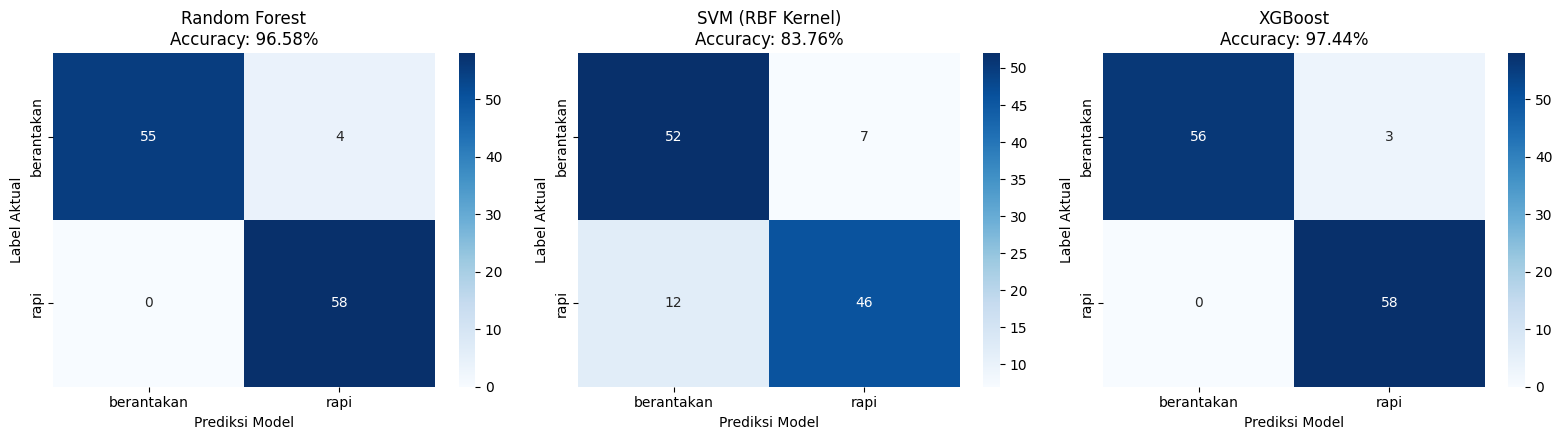


=== TABEL PERBANDINGAN MODEL ===


,Model,Test Accuracy (%),5-Fold CV Mean (%),CV Std (%)
2,XGBoost,97.44,69.07,12.04
0,Random Forest,96.58,67.70,9.48
1,SVM (RBF Kernel),83.76,75.60,6.40



🏆 MODEL TERBAIK: XGBoost (Akurasi: 97.44%)

=== CLASSIFICATION REPORT MODEL TERBAIK ===
              precision    recall  f1-score   support

  berantakan       1.00      0.95      0.97        59
        rapi       0.95      1.00      0.97        58

    accuracy                           0.97       117
   macro avg       0.98      0.97      0.97       117
weighted avg       0.98      0.97      0.97       117



In [6]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Baca kembali data dari CSV
df = pd.read_csv("dataset_fitur_sandal_14fitur.csv")

# 2. Pilih kolom fitur yang digunakan untuk training
# Menggunakan 9 fitur warna + 20 fitur GLCM per sudut + 5 fitur GLCM rata-rata
feature_cols = [col for col in df.columns if col not in ['Nama_File', 'Label']]
X = df[feature_cols]

# Encode label: berantakan = 0, rapi = 1
le = LabelEncoder()
y = le.fit_transform(df['Label'])

# 3. Split data Train (80%) dan Test (20%) dengan stratify agar proporsi kelas seimbang
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Normalisasi fitur (Sangat penting untuk SVM karena skala RGB dan GLCM berbeda jauh)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Inisialisasi 3 kandidat model
models = {
    "Random Forest": RandomForestClassifier(n_estimators=150, random_state=42),
    "SVM (RBF Kernel)": SVC(kernel='rbf', C=1.0, probability=True, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.1, eval_metric='logloss', random_state=42)
}

# 6. Latih dan evaluasi masing-masing model
results = []
trained_models = {}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for idx, (name, model) in enumerate(models.items()):
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    cv_scores = cross_val_score(model, scaler.fit_transform(X), y, cv=5)

    results.append({
        "Model": name,
        "Test Accuracy (%)": round(acc * 100, 2),
        "5-Fold CV Mean (%)": round(cv_scores.mean() * 100, 2),
        "CV Std (%)": round(cv_scores.std() * 100, 2)
    })
    trained_models[name] = (model, y_pred, acc)

    # Plot Confusion Matrix untuk masing-masing model
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
        xticklabels=le.classes_, yticklabels=le.classes_
    )
    axes[idx].set_title(f"{name}\nAccuracy: {acc*100:.2f}%")
    axes[idx].set_xlabel("Prediksi Model")
    axes[idx].set_ylabel("Label Aktual")

plt.tight_layout()
plt.show()

# 7. Tampilkan Tabel Perbandingan Akurasi & Pilih Model Terbaik
df_results = pd.DataFrame(results).sort_values(by="Test Accuracy (%)", ascending=False)
print("\n=== TABEL PERBANDINGAN MODEL ===")
display(df_results)

best_model_name = df_results.iloc[0]["Model"]
best_model, best_pred, best_acc = trained_models[best_model_name]

print(f"\n🏆 MODEL TERBAIK: {best_model_name} (Akurasi: {best_acc*100:.2f}%)")
print("\n=== CLASSIFICATION REPORT MODEL TERBAIK ===")
print(classification_report(y_test, best_pred, target_names=le.classes_))

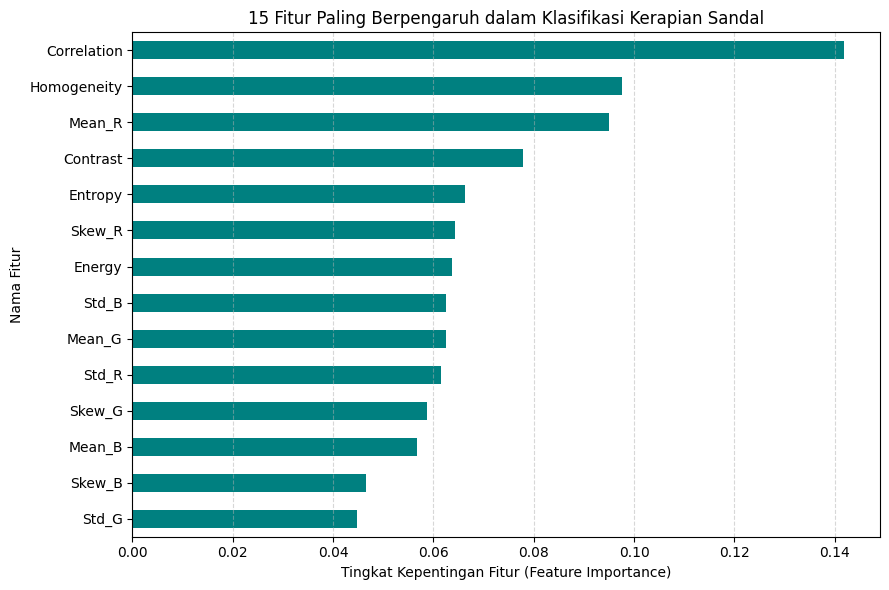

In [7]:
# Ambil nilai Feature Importance dari Random Forest
rf_model = trained_models["Random Forest"][0]
importances = pd.Series(rf_model.feature_importances_, index=feature_cols)
top_15_features = importances.sort_values(ascending=True).tail(15)

plt.figure(figsize=(9, 6))
top_15_features.plot(kind='barh', color='teal')
plt.title("15 Fitur Paling Berpengaruh dalam Klasifikasi Kerapian Sandal")
plt.xlabel("Tingkat Kepentingan Fitur (Feature Importance)")
plt.ylabel("Nama Fitur")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 6. Training Model XGBoost & Export ke File `.joblib`

Bagian ini melatih model **XGBoost Classifier** menggunakan 14 fitur hasil ekstraksi dan menyimpannya ke dalam file `.joblib` bersama artefak pendukungnya (PowerTransformer, LabelEncoder, dan nama fitur) agar siap digunakan untuk deployment atau inferensi citra baru.

In [9]:
# =====================================================================
# TRAINING MODEL XGBOOST & EXPORT KE FILE JOBLIB
# =====================================================================
import os
import joblib
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer, LabelEncoder
from xgboost import XGBClassifier

# 1. Load dataset CSV 14 fitur
csv_filename = "dataset_fitur_sandal_14fitur.csv"
df = pd.read_csv(csv_filename)

feature_cols = [c for c in df.columns if c not in ['Label', 'Nama_File']]
X = df[feature_cols]

# 2. Encode label kelas (berantakan: 0, rapi: 1)
le = LabelEncoder()
y = le.fit_transform(df['Label'])

# 3. Split data Train (80%) dan Test (20%) dengan Stratify
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Normalisasi fitur dengan PowerTransformer (Yeo-Johnson)
pt = PowerTransformer(method='yeo-johnson')
X_train_scaled = pt.fit_transform(X_train)
X_test_scaled = pt.transform(X_test)

# 5. Inisialisasi & latih model XGBoost
xgb_model = XGBClassifier(
    n_estimators=250,
    max_depth=6,
    learning_rate=0.08,
    subsample=0.9,
    eval_metric='logloss',
    random_state=42
)
xgb_model.fit(X_train_scaled, y_train)

# 6. Simpan paket model & artefak ke file .joblib
joblib_filename = "model_xgboost_kerapian.joblib"
model_artifacts = {
    'model': xgb_model,
    'transformer': pt,
    'label_encoder': le,
    'feature_names': feature_cols,
    'classes': list(le.classes_)
}
joblib.dump(model_artifacts, joblib_filename)

print(f"✅ Model XGBoost dan artefak berhasil disimpan ke file: '{joblib_filename}'")
print(f"   - Jumlah fitur: {len(feature_cols)}")
print(f"   - Daftar kelas: {list(le.classes_)}")


✅ Model XGBoost dan artefak berhasil disimpan ke file: 'model_xgboost_kerapian.joblib'
   - Jumlah fitur: 14
   - Daftar kelas: ['berantakan', 'rapi']


## 7. Pengujian & Evaluasi Hasil Modeling XGBoost

Pengujian dilakukan dalam 2 tahap:
1. **Evaluasi Test Set**: Menghitung Akurasi, Classification Report, dan Confusion Matrix Heatmap dengan me-load model dari file `.joblib`.
2. **Uji Inferensi Citra Baru**: Fungsi `predict_image()` untuk memprediksi label kerapian langsung dari file gambar foto.

=== HASIL EVALUASI MODEL XGBOOST PADA DATA TEST ===
🎯 Test Accuracy: 97.44%

--- Classification Report ---
              precision    recall  f1-score   support

  berantakan       1.00      0.95      0.97        59
        rapi       0.95      1.00      0.97        58

    accuracy                           0.97       117
   macro avg       0.98      0.97      0.97       117
weighted avg       0.98      0.97      0.97       117



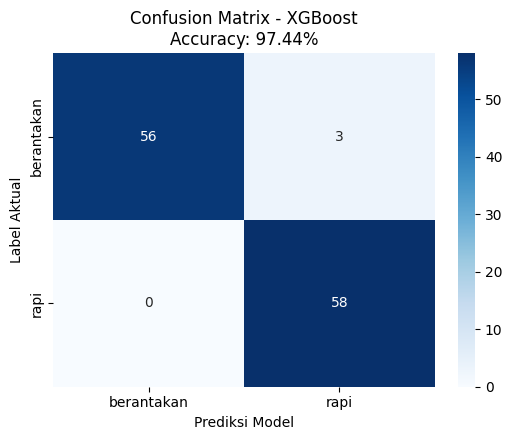

In [10]:
# =====================================================================
# PENGUJIAN 1: EVALUASI PERFORMA MODEL PADA DATA TEST DARI JOBLIB
# =====================================================================
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load artefak model dari file .joblib
artifacts = joblib.load("model_xgboost_kerapian.joblib")
loaded_model = artifacts['model']
loaded_le = artifacts['label_encoder']

# Prediksi pada data uji (X_test_scaled)
y_pred = loaded_model.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)

print("=== HASIL EVALUASI MODEL XGBOOST PADA DATA TEST ===")
print(f"🎯 Test Accuracy: {acc * 100:.2f}%")
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=loaded_le.classes_))

# Visualisasi Confusion Matrix
plt.figure(figsize=(5.5, 4.5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=loaded_le.classes_, yticklabels=loaded_le.classes_
)
plt.title(f"Confusion Matrix - XGBoost\nAccuracy: {acc*100:.2f}%")
plt.xlabel("Prediksi Model")
plt.ylabel("Label Aktual")
plt.tight_layout()
plt.show()



--- PENGUJIAN SAMPEL KELAS RAPI ---


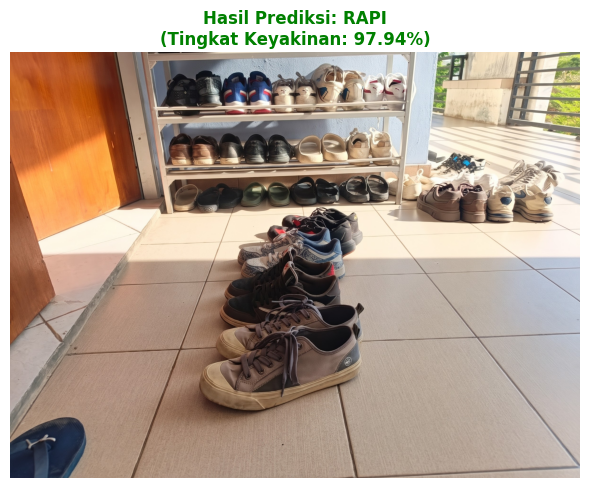

File Citra   : 24-003 Rapi 2.jpg
Prediksi     : RAPI
Confidence   : 97.94%
Probabilitas tiap kelas:
  - berantakan: 2.06%
  - rapi: 97.94%

--- PENGUJIAN SAMPEL KELAS BERANTAKAN ---


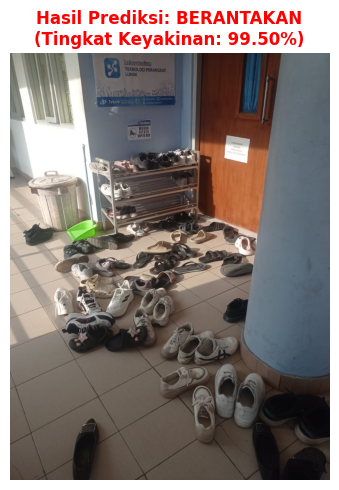

File Citra   : 24-003 Berantakan 2.jpg
Prediksi     : BERANTAKAN
Confidence   : 99.50%
Probabilitas tiap kelas:
  - berantakan: 99.50%
  - rapi: 0.50%


In [11]:
# =====================================================================
# PENGUJIAN 2: TEST PREDIKSI CITRA GAMBAR LANGSUNG DENGAN MODEL JOBLIB
# =====================================================================
def predict_image(image_path, model_joblib_path="model_xgboost_kerapian.joblib", show_plot=True):
    """
    Fungsi untuk memprediksi label kerapian suatu citra foto menggunakan model XGBoost .joblib
    """
    # 1. Load model & artefak dari file .joblib
    artifacts = joblib.load(model_joblib_path)
    model = artifacts['model']
    transformer = artifacts['transformer']
    feature_names = artifacts['feature_names']
    classes = artifacts['classes']

    # 2. Baca gambar
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        raise FileNotFoundError(f"Gambar tidak ditemukan: {image_path}")

    # 3. Ekstraksi 14 fitur
    features_dict = extract_14_features_pro(img_bgr)
    df_single = pd.DataFrame([features_dict])[feature_names]

    # 4. Transformasi fitur & Prediksi
    X_single_scaled = transformer.transform(df_single)
    pred_idx = model.predict(X_single_scaled)[0]
    pred_proba = model.predict_proba(X_single_scaled)[0]

    predicted_label = classes[pred_idx]
    confidence = pred_proba[pred_idx] * 100

    # 5. Visualisasi hasil prediksi pada citra
    if show_plot:
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(6, 5))
        plt.imshow(img_rgb)
        plt.title(f"Hasil Prediksi: {predicted_label.upper()}\n(Tingkat Keyakinan: {confidence:.2f}%)",
                  fontsize=12, color='green' if predicted_label == 'rapi' else 'red', fontweight='bold')
        plt.axis('off')
        plt.tight_layout()
        plt.show()

        print(f"File Citra   : {os.path.basename(image_path)}")
        print(f"Prediksi     : {predicted_label.upper()}")
        print(f"Confidence   : {confidence:.2f}%")
        print("Probabilitas tiap kelas:")
        for cls, prob in zip(classes, pred_proba):
            print(f"  - {cls}: {prob*100:.2f}%")

    return predicted_label, confidence

# --- Demo Pengujian pada Sampel Gambar Rapi & Berantakan ---
rapi_folder = os.path.join(output_dir, 'rapi') if 'output_dir' in locals() and os.path.exists(os.path.join(output_dir, 'rapi')) else 'foto-psd/rapi'
berantakan_folder = os.path.join(output_dir, 'berantakan') if 'output_dir' in locals() and os.path.exists(os.path.join(output_dir, 'berantakan')) else 'foto-psd/berantakan'

# Ambil 1 sampel dari kelas rapi
if os.path.exists(rapi_folder):
    sample_rapi = [os.path.join(rapi_folder, f) for f in os.listdir(rapi_folder) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]
    if sample_rapi:
        print("\n--- PENGUJIAN SAMPEL KELAS RAPI ---")
        predict_image(sample_rapi[0])

# Ambil 1 sampel dari kelas berantakan
if os.path.exists(berantakan_folder):
    sample_berantakan = [os.path.join(berantakan_folder, f) for f in os.listdir(berantakan_folder) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]
    if sample_berantakan:
        print("\n--- PENGUJIAN SAMPEL KELAS BERANTAKAN ---")
        predict_image(sample_berantakan[0])
